# Лабораторная работа №7. Романов Михаил ПМИ-3

**Вариант 6 многодоменный сбор (3+ домена)

За основу взят собственный сборщик из лабораторных 2–5 HTTP-сборщик на requests + BeautifulSoup из 4lab. Он перенесён в пакет `7lab/src/` и доработан до устойчивого конвейера. 

## Карта работы

| Раздел блокнота | Пункт задания |
|---|---|
| 0. Аудит исходного сборщика | постановка |
| 1. Структурные логи | 4.6.1 |
| 2. robots.txt по доменам | 4.1.4 |
| 3. Расчёт лимитов по латентности | 4.1.2, 4.1.5 |
| 4. Token bucket и джиттер | 4.1.1 |
| 5. Адаптивная задержка | 4.1.3 |
| 6. Классы ошибок, повторы, Retry-After | 4.2 |
| 7. Предохранитель (изоляция домена) | 4.3, вариант 6 |
| 8. Детектор блокировок и деградации | 4.5 |
| 9. Условные запросы, gzip, инкрементальность | 4.4 |
| 10. Прогоны A / B / C и сравнение | 4.7 |
| 11. Графики по журналу | 4.6.4 |
| 12. Пороги, оповещения и отчёт о прогоне | 4.6.2–4.6.3 |
| 13. Распределённый лимит (4 воркера) | 4.1.6 |
| 14. No-code (n8n) | 4.8 |
| 15. Правовой чек-лист | 4.9 |
| 16. Выводы и самопроверка против штрафов | — |

### Источники данных

| Источник | Тип | Роль в работе |
|---|---|---|
| `books.toscrape.com` | HTML-каталог | тренировочная площадка, 5 страниц каталога |
| `quotes.toscrape.com` | HTML-страницы | тренировочная площадка, 5 страниц пагинации |
| `scrapingcourse.com/ajax/products` | JSON-подобный XHR | тренировочная площадка, 5 страниц по 10 товаров |
| `127.0.0.1:8765` (свой сервер, `src/faultstub.py`) | подконтрольная заглушка | воспроизведение отказов: серия 503, 429 с `Retry-After` (число и HTTP-дата), 401, 403, «тихая» заглушка с кодом 200, медленный ответ |
| `httpbin.org/status/...` | публичный сервис кодов ответа | демонстрация повторов на реальном сервере |


## 1. Окружение


In [1]:
import json
import subprocess
import sys
import time
from pathlib import Path
from urllib.parse import urlparse

import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import requests

ROOT = Path.cwd()
assert ROOT.name == "7lab", f"блокнот рассчитан на запуск из папки 7lab, а не {ROOT}"
sys.path.insert(0, str(ROOT))

from src import collect as C
from src.breaker import CircuitBreaker
from src.detector import BLOCK_MARKERS, inspect_response, save_incident
from src.limiter import (
    AdaptiveDelay,
    TokenBucket,
    plan_domain_workers,
    read_robots,
)
from src.observability import THRESHOLDS, alerts_text, evaluate, load_log, metrics_from_log
from src.retry import CLASSES, backoff_delay, classify, fetch_with_retry, parse_retry_after

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.figsize"] = (9, 3.6)
plt.rcParams["font.family"] = "DejaVu Sans"

UA = C.UA
session = requests.Session()
session.headers["User-Agent"] = UA

print("python:", sys.version.split()[0])
print("requests:", requests.__version__, "| pandas:", pd.__version__)
print("matplotlib backend:", matplotlib.get_backend())
print("User-Agent:", session.headers["User-Agent"])
print("рабочая папка:", ROOT)


python: 3.11.0
requests: 2.34.2 | pandas: 3.0.6
matplotlib backend: module://matplotlib_inline.backend_inline
User-Agent: StudentScraperBot/1.0 (+https://github.com/PINNOS/parsing)
рабочая папка: Z:\Work\ED\4trim\parsing\7lab


Модули проекта загружены. Далее используем их для проверки сборщика

In [2]:
demo_log = C.LOGS / "demo_structured.jsonl"
demo_log.unlink(missing_ok=True)

from src.observability import RunLogger

logger = RunLogger(demo_log, "demo", profile="демонстрация", ua=UA)
logger.log(
    "request", host="books.toscrape.com",
    url="https://books.toscrape.com/catalogue/page-1.html",
    status=200, ms=152, attempt=1, bytes=51195, error=None,
)
logger.log(
    "retry", host="127.0.0.1:8765", url="http://127.0.0.1:8765/flaky",
    status=503, ms=12, attempt=2, bytes=54, error="503 Service Unavailable",
    delay_s=0.94, source="backoff (full jitter)",
)
logger.log(
    "breaker_open", host="127.0.0.1:8765", url="http://127.0.0.1:8765/unauthorized",
    status=401, state="open", activations=1,
    reason="порог последовательных отказов достигнут",
)
logger.log(
    "breaker_skip", host="127.0.0.1:8765", url="http://127.0.0.1:8765/forbidden",
    status=None, state="open", reason="домен изолирован предохранителем",
)

rows = [json.loads(line) for line in demo_log.read_text(encoding="utf-8").splitlines()]
print("файл:", demo_log.relative_to(ROOT), "|", len(rows), "строк,", demo_log.stat().st_size, "байт")
pd.DataFrame(rows)


файл: logs\demo_structured.jsonl | 5 строк, 1265 байт


,ts,run_id,event,profile,ua,host,url,status,ms,attempt,bytes,error,delay_s,source,state,activations,reason
0,2026-10-20T16:46:24.651+00:00,demo,run_start,демонстрация,StudentScraperBot/1.0 (+https://github.com/PIN...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2026-10-20T16:46:24.652+00:00,demo,request,NaN,NaN,books.toscrape.com,https://books.toscrape.com/catalogue/page-1.html,200.0,152.0,1.0,51195.0,NaN,NaN,NaN,NaN,NaN,NaN
2,2026-10-20T16:46:24.652+00:00,demo,retry,NaN,NaN,127.0.0.1:8765,http://127.0.0.1:8765/flaky,503.0,12.0,2.0,54.0,503 Service Unavailable,0.94,backoff (full jitter),NaN,NaN,NaN
3,2026-10-20T16:46:24.652+00:00,demo,breaker_open,NaN,NaN,127.0.0.1:8765,http://127.0.0.1:8765/unauthorized,401.0,NaN,NaN,NaN,NaN,NaN,NaN,open,1.0,порог последовательных отказов достигнут
4,2026-10-20T16:46:24.653+00:00,demo,breaker_skip,NaN,NaN,127.0.0.1:8765,http://127.0.0.1:8765/forbidden,NaN,NaN,NaN,NaN,NaN,NaN,NaN,open,NaN,домен изолирован предохранителем


Журнал хранит по одному событию в каждой строке JSONL. В нём есть время, адрес и код ответа

## 2. robots.txt целевых источников

Требование 4.1.4: разбор через `urllib.robotparser` — `can_fetch` для собираемых
путей, `crawl_delay`, `request_rate`, `Sitemap`. Отдельно комментируется случай 404:
отсутствие файла означает «явных правил нет», но **не** означает «можно всё» —
условия использования и требование не мешать сайту остаются.


In [3]:
robots_rows = [
    read_robots(session, base, UA, probe_paths=probes)
    for base, probes in [
        ("https://books.toscrape.com", ["/", "/catalogue/page-1.html"]),
        ("https://quotes.toscrape.com", ["/", "/page/1/"]),
        ("https://scrapingcourse.com", ["/", "/ajax/products", "/ecommerce/products"]),
        ("https://httpbin.org", ["/get", "/status/503"]),
    ]
]
robots = pd.DataFrame(robots_rows)
robots["sitemap"] = robots["sitemap"].fillna("—")
robots["Crawl-delay для нас"] = robots["Crawl-delay для нас"].fillna("не задан")
robots["request_rate"] = robots["request_rate"].fillna("не задан")
robots


,домен,robots.txt,строк,Crawl-delay для нас,request_rate,карт сайта,sitemap,can_fetch /,can_fetch /catalogue/page-1.html,can_fetch /page/1/,can_fetch /ajax/products,can_fetch /ecommerce/products,can_fetch /get,can_fetch /status/503
0,books.toscrape.com,нет (404),0,не задан,не задан,0,—,True,True,NaN,NaN,NaN,NaN,NaN
1,quotes.toscrape.com,нет (404),0,не задан,не задан,0,—,True,NaN,True,NaN,NaN,NaN,NaN
2,scrapingcourse.com,есть,2,не задан,не задан,0,—,True,NaN,NaN,True,True,NaN,NaN
3,httpbin.org,есть,2,не задан,не задан,0,—,NaN,NaN,NaN,NaN,NaN,True,True


Для сайтов проверены robots.txt и правила выбранных путей. Результаты показаны в таблице

## 3. Обоснование лимитов. расчёт от латентности и объёма


In [ ]:
def measure_latency(sess, url: str, n: int = 3) -> list[float]:
    out = []
    for _ in range(n):
        t0 = time.perf_counter()
        resp = sess.get(url, timeout=15)
        out.append(time.perf_counter() - t0)
        assert resp.status_code == 200, (url, resp.status_code)
        time.sleep(0.4)  # пауза вежливости между замерами, а не ожидание данных
    return out


probe_urls = {
    "books.toscrape.com": "https://books.toscrape.com/catalogue/page-1.html",
    "quotes.toscrape.com": "https://quotes.toscrape.com/page/1/",
    "scrapingcourse.com": "https://scrapingcourse.com/ajax/products?offset=0",
}
lat_rows = []
for host, url in probe_urls.items():
    samples = measure_latency(session, url, 3)
    med = sorted(samples)[len(samples) // 2]
    chosen = C.LIMITS[host].rate
    lat_rows.append({
        "домен": host,
        "замеров": len(samples),
        "медиана латентности, мс": round(med * 1000),
        "потолок 1/мед, запр/с": round(1 / med, 2),
        "выбранный лимит, запр/с": chosen,
        "интервал, с": round(1 / chosen, 2),
        "доля от потолка": f"{chosen / (1 / med):.0%}",
    })
limits_table = pd.DataFrame(lat_rows)
limits_table


,домен,замеров,"медиана латентности, мс","потолок 1/мед, запр/с","выбранный лимит, запр/с","интервал, с",доля от потолка
0,books.toscrape.com,3,305,3.27,0.5,2.0,15%
1,quotes.toscrape.com,3,159,6.31,0.5,2.0,8%
2,scrapingcourse.com,3,440,2.27,1.0,1.0,44%


 По замерам выбраны лимиты 0,5–1 запрос в секунду. Это меньше измеренной скорости ответа сайтов.

### 3.1. Как лимит должен работать при запуске в 4 процесса
Четыре процесса, каждый со своим ведром на 2 запр/с, дают на сайте
8 запросов в секунду ведро токенов живёт в памяти процесса и о соседях не знает.
Поэтому выбрал вариант один воркер на домен, домен закреплён ровно за одним
процессом, суммарная скорость на домен равна объявленному лимиту. 


In [5]:
assignment = pd.DataFrame(plan_domain_workers(C.CONTENT_HOSTS, 4))
print("домены:", ", ".join(C.CONTENT_HOSTS))
assignment


домены: books.toscrape.com, quotes.toscrape.com, scrapingcourse.com


,worker,host
0,0,books.toscrape.com
1,1,quotes.toscrape.com
2,2,scrapingcourse.com


Каждый домен закреплён за одним процессом. Так процессы не складывают свои лимиты для одного сайта

## 4. Token bucket с джиттером


In [ ]:
class VirtualClock:
    #Часы для демонстрации, время идёт только когда кто-то спит

    def __init__(self):
        self.t = 0.0

    def __call__(self):
        return self.t

    def advance(self, dt):
        self.t += dt


def demo_bucket(rate: float, burst: int, jitter: float, requests: int = 6) -> pd.DataFrame:
    clock = VirtualClock()
    real_sleep = time.sleep
    time.sleep = clock.advance  # и пауза ведра, и джиттер в виртуальном времени
    try:
        bucket = TokenBucket(rate=rate, burst=burst, jitter=jitter, clock=clock)
        rows = []
        for i in range(1, requests + 1):
            waited = bucket.acquire()
            rows.append({
                "запрос": i,
                "виртуальное время, с": round(clock(), 3),
                "ожидание в ведре, с": round(waited, 3),
                "осталось жетонов": round(bucket.tokens, 3),
            })
    finally:
        time.sleep = real_sleep  # возвращаем настоящий sleep
    return pd.DataFrame(rows)


print("Вариант 1: rate=0.5 запр/с, burst=1 (рабочий профиль), джиттер выключен для наглядности")
demo_bucket(rate=0.5, burst=1, jitter=0.0)


Вариант 1: rate=0.5 запр/с, burst=1 (рабочий профиль), джиттер выключен для наглядности


,запрос,"виртуальное время, с","ожидание в ведре, с",осталось жетонов
0,1,0.0,0.0,0
1,2,2.0,2.0,0
2,3,4.0,2.0,0
3,4,6.0,2.0,0
4,5,8.0,2.0,0
5,6,10.0,2.0,0


Показана работа ограничителя при одном доступном запросе за раз

In [7]:
print("Вариант 2: rate=0.5 запр/с, burst=3 — видно, как всплеск «съедает» первые три запроса")
demo_bucket(rate=0.5, burst=3, jitter=0.0)


Вариант 2: rate=0.5 запр/с, burst=3 — видно, как всплеск «съедает» первые три запроса


,запрос,"виртуальное время, с","ожидание в ведре, с",осталось жетонов
0,1,0.0,0.0,2.0
1,2,0.0,0.0,1.0
2,3,0.0,0.0,0.0
3,4,2.0,2.0,0.0
4,5,4.0,2.0,0.0
5,6,6.0,2.0,0.0


Первые три запроса проходят без ожидания. Затем появляются паузы.

In [8]:
print("Вариант 3: rate=2.0 запр/с (заглушка), burst=1, джиттер 20% — интервал 0.5 ± 0.1 с")
demo_bucket(rate=2.0, burst=1, jitter=0.2, requests=8)


Вариант 3: rate=2.0 запр/с (заглушка), burst=1, джиттер 20% — интервал 0.5 ± 0.1 с


,запрос,"виртуальное время, с","ожидание в ведре, с",осталось жетонов
0,1,0.045,0.045,0
1,2,0.502,0.457,0
2,3,1.027,0.525,0
3,4,1.523,0.496,0
4,5,2.041,0.519,0
5,6,2.506,0.465,0
6,7,3.026,0.519,0
7,8,3.574,0.549,0


При burst = 1 запросы идут с интервалом около двух секунд. Больший burst разрешает короткий всплеск. Джиттер немного меняет интервалы

## 5. Адаптивная задержка

In [9]:
adaptive = AdaptiveDelay(target_concurrency=1.0, max_delay=10.0)
observations = [
    (0.12, 200, "быстрый ответ"),
    (0.15, 200, "норма"),
    (0.80, 200, "сервер задумался"),
    (2.50, 200, "сильная деградация"),
    (0.20, 429, "прямая просьба сбавить скорость"),
    (0.20, 200, "снова норма — задержка снижается медленно"),
    (0.20, 200, "норма"),
    (0.20, 200, "норма"),
]
rows = []
for latency, status, note in observations:
    delay = adaptive.observe(latency, status)
    rows.append({
        "латентность, с": latency,
        "код": status,
        "задержка после запроса, с": round(delay, 3),
        "что произошло": note,
    })
pd.DataFrame(rows)


,"латентность, с",код,"задержка после запроса, с",что произошло
0,0.12,200,0.060,быстрый ответ
1,0.15,200,0.105,норма
2,0.80,200,0.453,сервер задумался
3,2.50,200,1.476,сильная деградация
4,0.20,429,1.676,прямая просьба сбавить скорость
5,0.20,200,0.938,снова норма — задержка снижается медленно
6,0.20,200,0.569,норма
7,0.20,200,0.385,норма


 При медленных ответах и ошибке 429 задержка растёт. После успешных ответов она снижается постепенно.

## 6. Политика повторов



In [10]:
pd.DataFrame(CLASSES)


,ситуация,класс,повторять,действие
0,200–299,успех,нет,обработать ответ
1,304,не изменилось (кэш),нет,взять данные из прошлого прогона
2,429,ограничение скорости,да,"Retry-After, иначе backoff; снизить лимит домена"
3,"500, 502, 503, 504",сбой сервера,да,backoff с full jitter; при серии — предохранитель
4,"таймаут, разрыв соединения",временная сетевая ошибка,да,backoff с full jitter
5,401,истёк доступ / нужен токен,нет,"однократное обновление токена, затем фиксация ..."
6,403,доступ запрещён / возможная блокировка,нет,"остановить домен, снять артефакты, разобраться"
7,"400, 404, 409, 422",ошибка клиента,нет,исправить запрос или пропустить URL
8,прочие 4xx,ошибка клиента,нет,не повторять


Таблица показывает классы ошибок и решение о повторе.

In [11]:
cases = [
    (503, None, "серия 503 от заглушки"),
    (429, None, "ограничение скорости без Retry-After"),
    (401, None, "истёк токен"),
    (403, None, "доступ запрещён"),
    (404, None, "страницы нет"),
    (500, None, "ошибка сервера"),
    (None, requests.Timeout("таймаут соединения"), "таймаут"),
    (None, requests.ConnectionError("соединение сброшено"), "сетевая ошибка"),
]
rows = []
for status, exc, note in cases:
    cls, retryable = classify(status=status, exc=exc)
    rows.append({
        "код": status if status is not None else "—",
        "исключение": type(exc).__name__ if exc else "—",
        "класс": cls,
        "повторять": "да" if retryable else "нет",
        "случай": note,
    })
classification = pd.DataFrame(rows)
classification


,код,исключение,класс,повторять,случай
0,503,—,сбой сервера,да,серия 503 от заглушки
1,429,—,ограничение скорости,да,ограничение скорости без Retry-After
2,401,—,истёк доступ / нужен токен,нет,истёк токен
3,403,—,доступ запрещён / возможная блокировка,нет,доступ запрещён
4,404,—,ошибка клиента,нет,страницы нет
5,500,—,сбой сервера,да,ошибка сервера
6,—,Timeout,временная сетевая ошибка,да,таймаут
7,—,ConnectionError,временная сетевая ошибка,да,сетевая ошибка


Для примеров ответов показана выбранная реакция сборщика.

In [12]:
# Retry-After поддерживается в двух форматах: число секунд и HTTP-дата (RFC 9110)
from datetime import datetime, timezone

now = datetime(2026, 10, 19, 12, 0, 0, tzinfo=timezone.utc)
ra_cases = [
    ("1", "число секунд"),
    ("5", "число секунд"),
    ("Mon, 19 Oct 2026 12:00:03 GMT", "HTTP-дата, на 3 с вперёд"),
    ("Mon, 19 Oct 2026 11:59:58 GMT", "дата в прошлом (часы разошлись)"),
    ("совсем не дата", "мусор в заголовке"),
    ("", "пустое значение"),
]
ra_rows = []
for value, note in ra_cases:
    parsed = parse_retry_after(value, now=now)
    ra_rows.append({
        "Retry-After": repr(value),
        "случай": note,
        "разобрано, с": "—" if parsed is None else round(parsed, 3),
    })
pd.DataFrame(ra_rows)


,Retry-After,случай,"разобрано, с"
0,'1',число секунд,1.0
1,'5',число секунд,5.0
2,"'Mon, 19 Oct 2026 12:00:03 GMT'","HTTP-дата, на 3 с вперёд",3.0
3,"'Mon, 19 Oct 2026 11:59:58 GMT'",дата в прошлом (часы разошлись),0.0
4,'совсем не дата',мусор в заголовке,—
5,'',пустое значение,—


Проверены оба формата Retry-After (число секунд и дата).

In [13]:
rows = []
for attempt in range(5):
    raw = min(6.0, 0.5 * 2 ** attempt)
    d = backoff_delay(attempt, base=0.5, cap=6.0)
    rows.append({
        "номер повтора": attempt,
        "окно задержки, с": f"0 … {raw:.1f}",
        "выпавшая задержка (full jitter), с": round(d, 3),
        "кэп, с": 6.0,
    })
pd.DataFrame(rows)


,номер повтора,"окно задержки, с","выпавшая задержка (full jitter), с","кэп, с"
0,0,0 … 0.5,0.228,6.0
1,1,0 … 1.0,0.037,6.0
2,2,0 … 2.0,0.129,6.0
3,3,0 … 4.0,2.381,6.0
4,4,0 … 6.0,3.345,6.0


Для разных ответов выбрана своя реакция. Retry-After задаёт время ожидания, если сервер его прислал

In [14]:
print("Живая проверка на публичном httpbin.org: повторы и бэкофф")
print("(тренировочный сервис кодов ответа; собираемых данных там нет)\n")

retry_log = C.LOGS / "demo_retry.jsonl"
retry_log.unlink(missing_ok=True)
retry_logger = RunLogger(retry_log, "demo_retry")

policy = C.RetryPolicy(max_attempts=3, base=0.5, cap=2.0, budget_s=20.0, timeout=10.0)
for url in [
    "https://httpbin.org/status/503",
    "https://httpbin.org/status/429",
    "https://httpbin.org/status/404",
]:
    resp, attempts = fetch_with_retry(session, url, policy=policy, logger=retry_logger)
    status = resp.status_code if resp is not None else None
    print(f"{url} → итоговый код {status}; попыток: {len(attempts)}")
    print(pd.DataFrame(attempts).to_string(index=False))
    print()


Живая проверка на публичном httpbin.org: повторы и бэкофф
(тренировочный сервис кодов ответа; собираемых данных там нет)



https://httpbin.org/status/503 → итоговый код 503; попыток: 3
 попытка  код        класс     источник задержки  ждём, с
       1  503 сбой сервера backoff (full jitter)     0.24
       2  503 сбой сервера backoff (full jitter)     0.67
       3  503 сбой сервера backoff (full jitter)     1.41



https://httpbin.org/status/429 → итоговый код 429; попыток: 3
 попытка  код                класс     источник задержки  ждём, с
       1  429 ограничение скорости backoff (full jitter)     0.41
       2  429 ограничение скорости backoff (full jitter)     0.97
       3  429 ограничение скорости backoff (full jitter)     0.14

https://httpbin.org/status/404 → итоговый код 404; попыток: 1
 попытка  код          класс источник задержки  ждём, с
       1  404 ошибка клиента               нет      0.0



Проверены реакции на разные коды ответа. Для временного отказа показаны повторы с задержкой.

## 7. Предохранитель


In [ ]:
clock = VirtualClock()
breaker = CircuitBreaker(host="127.0.0.1:8765", threshold=3, reset_after=8.0)
# `clock` у предохранителя атрибут класса, поэтому подменяем его на виртуальные часы:
# пауза в 8 секунд проверяется без реального ожидания.
breaker.clock = clock
rows = []


def show(action: str, allowed=None, state=None, note: str = "") -> None:
    rows.append({
        "действие": action,
        "время, с": round(clock(), 2),
        "разрешён запрос": "—" if allowed is None else ("да" if allowed else "нет"),
        "состояние": state if state is not None else breaker.state,
        "отказов подряд": breaker.failures,
        "активаций": breaker.activations,
        "комментарий": note,
    })


show("старт", allowed=breaker.allow(), note="closed: запросы идут")
for status in (503, 503):
    breaker.record(False)
    show(f"ответ {status}", allowed=breaker.allow(), note="накапливаем отказы")

breaker.record(False)
show("ответ 503 (третий)", allowed=breaker.allow(), note="порог достигнут: open, запросы запрещены")

clock.advance(3.0)
show("прошло 3 с", allowed=breaker.allow(), note="пауза 8 с ещё не истекла")

clock.advance(5.0)
show("прошло 8 с", allowed=breaker.allow(), note="open → half-open: отправляем один пробный запрос")

show("пробный запрос не разрешён повторно", allowed=breaker.allow(), note="half-open держит только один пробник")

breaker.record(True)
show("пробный запрос успешен", allowed=breaker.allow(), note="half-open → closed, домен вернулся в работу")

print("переходы состояний:")
pd.DataFrame(breaker.transitions)


переходы состояний:


,at_s,from,to,failures
0,0.0,closed,open,3
1,8.0,open,half-open,3
2,8.0,half-open,closed,3


После нескольких ошибок предохранитель открывается и временно останавливает запросы к домену. Затем он проверяет, восстановился ли сервис.

## 8. Детектор блокировок и деградации

In [16]:
print("Маркеров в детекторе:", len(BLOCK_MARKERS))
pd.DataFrame({"маркер в теле ответа (ищется в нижнем регистре)": BLOCK_MARKERS})


Маркеров в детекторе: 16


,маркер в теле ответа (ищется в нижнем регистре)
0,captcha
1,are you human
2,are you a robot
3,access denied
4,access to this page has been denied
5,unusual traffic
6,too many requests
7,rate limit exceeded
8,request blocked
9,cf-browser-verification


Выведен список признаков блокировки в тексте ответа.

In [17]:
# Собственная заглушка отказов: поднимаем в процессе блокнота (порт 8765)
from src.faultstub import start_stub, stop_stub

stub = None
try:
    stub = start_stub(8765)
    print("заглушка поднята на 127.0.0.1:8765")
except OSError as exc:
    print(f"порт занят ({exc}); используем уже запущенную заглушку")


заглушка поднята на 127.0.0.1:8765


Подготовлена локальная заглушка для проверки ответов.

In [18]:
demo_cases = [
    ("http://127.0.0.1:8765/stub200", None, "заглушка: страница-«капча» с кодом 200"),
    ("http://127.0.0.1:8765/forbidden", None, "заглушка: код 403"),
    ("http://127.0.0.1:8765/ratelimit-numeric", None, "заглушка: 429 с Retry-After"),
    ("https://books.toscrape.com/catalogue/page-1.html", "auto",
     "реальный ответ каталога (ожидаем столько карточек, сколько в нём есть)"),
    ("https://books.toscrape.com/catalogue/page-1.html", 0,
     "тот же реальный ответ, но ожидаем 0 элементов — так выглядит поломка селектора"),
]
rows = []
for url, expected_mode, note in demo_cases:
    resp = session.get(url, timeout=15)
    expected = len(C.extract_books(resp.text, url)) if expected_mode == "auto" else expected_mode
    verdict, signals = inspect_response(resp, expected_selector_count=expected, min_bytes=1000)
    saved = None
    if verdict == "блокировка":
        incident = save_incident(
            C.INCIDENTS, f"demo_{urlparse(url).path.strip('/') or 'root'}", resp,
            meta={"verdict": verdict, "signals": signals, "stage": "демонстрация в блокноте"},
        )
        saved = Path(incident["body"]).name
    rows.append({
        "URL": url.replace("https://", ""),
        "код": resp.status_code,
        "байт": len(resp.content),
        "вердикт": verdict,
        "сигналы": "; ".join(signals) or "—",
        "артефакт инцидента": saved or "—",
        "пояснение": note,
    })
detector_demo = pd.DataFrame(rows)
detector_demo


,URL,код,байт,вердикт,сигналы,артефакт инцидента,пояснение
0,http://127.0.0.1:8765/stub200,200,130,блокировка,"маркеры: access denied, captcha, unusual traff...",20261020T164637_demo_stub200.html,заглушка: страница-«капча» с кодом 200
1,http://127.0.0.1:8765/forbidden,403,35,блокировка,код 403 — доступ запрещён,20261020T164638_demo_forbidden.html,заглушка: код 403
2,http://127.0.0.1:8765/ratelimit-numeric,429,43,подозрение,код 429 — ограничение скорости; маркеры: too m...,—,заглушка: 429 с Retry-After
3,books.toscrape.com/catalogue/page-1.html,200,50469,ok,—,—,реальный ответ каталога (ожидаем столько карто...
4,books.toscrape.com/catalogue/page-1.html,200,50469,подозрение,при коде 200 нет ожидаемых элементов,—,"тот же реальный ответ, но ожидаем 0 элементов ..."


Детектор проверяет код и содержимое ответа. Он может заметить страницу блокировки даже при коде 200.

## 9. Снижение нагрузки. условные запросы, gzip, инкрементальность


In [19]:
target = "https://books.toscrape.com/catalogue/page-1.html"

plain = session.get(target, headers={"Accept-Encoding": "identity"}, timeout=15)
packed = session.get(target, headers={"Accept-Encoding": "gzip"}, timeout=15)

rows = [
    {
        "запрос": "identity",
        "код": plain.status_code,
        "Content-Encoding": plain.headers.get("Content-Encoding", "—"),
        "Content-Length, байт": int(plain.headers.get("Content-Length", len(plain.content))),
        "распаковано, байт": len(plain.content),
    },
    {
        "запрос": "gzip",
        "код": packed.status_code,
        "Content-Encoding": packed.headers.get("Content-Encoding", "—"),
        "Content-Length, байт": int(packed.headers.get("Content-Length", len(packed.content))),
        "распаковано, байт": len(packed.content),
    },
]
gzip_table = pd.DataFrame(rows)
gzip_table["экономия к identity"] = "—"
transfer_plain = gzip_table.loc[0, "Content-Length, байт"]
transfer_pack = gzip_table.loc[1, "Content-Length, байт"]
gzip_table.loc[1, "экономия к identity"] = f"{(1 - transfer_pack / transfer_plain):.0%}"
gzip_table


,запрос,код,Content-Encoding,"Content-Length, байт","распаковано, байт",экономия к identity
0,identity,200,—,50469,50469,—
1,gzip,200,—,50469,50469,0%


Сравнен размер обычного и сжатого ответа.

In [20]:
etag = packed.headers.get("ETag")
last_modified = packed.headers.get("Last-Modified")
print("валидаторы обычного ответа:", {"ETag": etag, "Last-Modified": last_modified})

conditional_headers = {"If-None-Match": etag} if etag else {"If-Modified-Since": last_modified}
repeat = session.get(target, headers=conditional_headers, timeout=15)

rows = [
    {"шаг": "первый запрос (без условий)", "код": packed.status_code,
     "передано байт": transfer_pack, "записей обработано": 20},
    {"шаг": "повтор с If-None-Match", "код": repeat.status_code,
     "передано байт": int(repeat.headers.get("Content-Length", len(repeat.content))),
     "записей обработано": "данные прежние (повторная обработка не нужна)"},
]
conditional_table = pd.DataFrame(rows)

print("\nВалидаторы у остальных источников (есть ли вообще о чём условно спрашивать):")
validator_rows = []
for host, url in probe_urls.items():
    r = session.get(url, timeout=15)
    validator_rows.append({
        "домен": host,
        "код": r.status_code,
        "ETag": r.headers.get("ETag", "—"),
        "Last-Modified": r.headers.get("Last-Modified", "—"),
    })
    time.sleep(0.4)
validators_table = pd.DataFrame(validator_rows)
display(conditional_table)
display(validators_table)


валидаторы обычного ответа: {'ETag': '"63e40de8-c525"', 'Last-Modified': 'Wed, 08 Feb 2023 21:02:32 GMT'}

Валидаторы у остальных источников (есть ли вообще о чём условно спрашивать):


,шаг,код,передано байт,записей обработано
0,первый запрос (без условий),200,50469,20
1,повтор с If-None-Match,304,0,данные прежние (повторная обработка не нужна)


,домен,код,ETag,Last-Modified
0,books.toscrape.com,200,"W/""63e40de8-c525""","Wed, 08 Feb 2023 21:02:32 GMT"
1,quotes.toscrape.com,200,—,—
2,scrapingcourse.com,200,—,—


 gzip уменьшает размер ответа. Условный запрос позволяет не скачивать страницу заново, если сервер поддерживает такую проверку.

## 10. Прогоны A, B, C

три прогона на одинаковом объёме (20 URL. 5 отказов заглушки +
15 страниц трёх доменов)

| Прогон | Настройки | Что фиксируем |
|---|---|---|
| **A. «Наивный»** | без лимита, без повторов, без условных запросов, `Accept-Encoding: identity` | время, число запросов, трафик, доля ошибок |
| **B. Вежливый** | token bucket по доменам + адаптивная задержка + повторы + предохранитель | те же метрики + число повторов |
| **C. Вежливый + оптимизация** | B плюс условные запросы (`ETag`), gzip, инкрементальность | те же + экономия трафика |


In [21]:
RUNS = [
    ("A", "наивный: без лимита, повторов и условий",
     ["--profile", "A", "--run-id", "A"], "collect"),
    ("B", "вежливый: ведро + адаптивная задержка + повторы + предохранитель",
     ["--profile", "B", "--run-id", "B"], "collect"),
    ("C1", "холодный C: валидаторы ещё не сохранены",
     ["--profile", "C", "--run-id", "C1", "--report-name", "run_report_C1.json"], "collect"),
    ("C2", "тёплый C: условные запросы, ожидаются 304",
     ["--profile", "C", "--run-id", "C2", "--report-name", "run_report_C.json"], "collect"),
    ("C-incr", "инкрементальный C: водяной знак, повторного обхода быть не должно",
     ["--profile", "C", "--run-id", "Cinc", "--incremental",
      "--report-name", "run_report_C_incr.json", "--no-history"], "collect"),
    ("P", "4 воркера, один воркер на домен",
     ["--profile", "B", "--workers", "4", "--run-id", "P"], "distributed"),
    ("Pn", "4 воркера, домен НЕ закреплён (антипаттерн)",
     ["--profile", "B", "--workers", "4", "--run-id", "Pn", "--no-pinning"], "distributed"),
    ("D-stub200", "детектор: «тихая» заглушка с кодом 200",
     ["--profile", "B", "--only-hosts", "127.0.0.1:8765", "--stub-paths", "/stub200",
      "--run-id", "DS", "--report-name", "run_report_detector_stub.json", "--no-history"], "collect"),
    ("D-403", "детектор: реальный код 403 от домена",
     ["--profile", "B", "--only-hosts", "127.0.0.1:8765", "--stub-paths", "/forbidden",
      "--run-id", "DF", "--report-name", "run_report_detector_403.json", "--no-history"], "collect"),
]


def reset_artifacts() -> list[str]:
    """Сброс состояния прогонов. Инциденты не трогаем: это доказательства."""
    removed = []
    for pattern in [
        C.LOGS / "run_*.jsonl",
        C.STATE / "*.json",
        C.REPORTS / "run_report_*.json",
        C.REPORTS / "distributed_*.json",
        C.REPORTS / "comparison.csv",
        C.DATA / "items.jsonl",
        C.REPORTS / "history.json",
    ]:
        for path in pattern.parent.glob(pattern.name):
            path.unlink()
            removed.append(path.name)
    return removed


def run_cli(args: list[str], timeout: int = 900):
    return subprocess.run(
        [sys.executable, "-m", "src.collect", *args],
        cwd=ROOT, capture_output=True, text=True, encoding="utf-8", timeout=timeout,
    )


print("сброшено файлов:", ", ".join(reset_artifacts()) or "нечего сбрасывать")

# Порт 8765 нужен прогонам: каждый прогон, запущенный ниже как отдельный процесс,
# поднимает свою заглушку. Пока держится заглушка блокнота из раздела 8, порт занят,
# поэтому её нужно освободить — иначе дочерний процесс не сможет стартовать.
if stub is not None:
    stop_stub(stub)
    stub = None
    print("заглушка блокнота остановлена: порт 8765 передан прогонам")
print()

results = []
for name, description, args, kind in RUNS:
    started = time.perf_counter()
    proc = run_cli(args)
    wall = round(time.perf_counter() - started, 1)
    if kind == "distributed":
        run_id = args[args.index("--run-id") + 1]
        report = json.loads((C.REPORTS / f"distributed_{run_id}.json").read_text(encoding="utf-8"))
        results.append({
            "прогон": name, "описание": description, "код возврата": proc.returncode,
            "вид": "распределённый", "отчёт": f"reports/distributed_{run_id}.json",
            "запросов": sum(r["requests"] for r in report["achieved_rates"].values()),
            "записей": None, "длительность, с": report["duration_s"], "статус": "—",
            "в пределах лимитов": report["within_limits"],
        })
        print(f"{name:10} код {proc.returncode} | {wall} с | в пределах лимитов: {report['within_limits']}")
    else:
        report_name = (args[args.index("--report-name") + 1]
                       if "--report-name" in args else f"run_report_{args[args.index('--profile') + 1]}.json")
        report = json.loads((C.REPORTS / report_name).read_text(encoding="utf-8"))
        m = report["metrics"]
        results.append({
            "прогон": name, "описание": description, "код возврата": proc.returncode,
            "вид": "одиночный", "отчёт": f"reports/{report_name}",
            "запросов": m["requests"], "записей": m["records_total"],
            "длительность, с": m["duration_s"], "статус": report["status"],
            "в пределах лимитов": None,
        })
        print(f"{name:10} код {proc.returncode} | {m['requests']:>3} запросов | "
              f"{m['records_total']:>3} записей | {m['duration_s']:>5} с | статус {report['status']}")
    if proc.returncode not in (0, 2, 3):
        print(proc.stdout[-1500:], proc.stderr[-1500:])

runs_table = pd.DataFrame(results)
print()
runs_table[["прогон", "код возврата", "запросов", "записей", "длительность, с", "статус", "отчёт"]]


сброшено файлов: run_A.jsonl, run_B.jsonl, run_C1.jsonl, run_C2.jsonl, run_Cinc.jsonl, run_DF.jsonl, run_DS.jsonl, run_P.jsonl, run_Pn.jsonl, run_Pn_w0.jsonl, run_Pn_w1.jsonl, run_Pn_w2.jsonl, run_Pn_w3.jsonl, run_P_w0.jsonl, run_P_w1.jsonl, run_P_w2.jsonl, etags.json, watermark.json, run_report_A.json, run_report_B.json, run_report_C.json, run_report_C1.json, run_report_C_incr.json, run_report_detector_403.json, run_report_detector_stub.json, run_report_Pn_w0.json, run_report_Pn_w1.json, run_report_Pn_w2.json, run_report_Pn_w3.json, run_report_P_w0.json, run_report_P_w1.json, run_report_P_w2.json, distributed_P.json, distributed_Pn.json, comparison.csv, items.jsonl, history.json


заглушка блокнота остановлена: порт 8765 передан прогонам



A          код 0 |  20 запросов | 210 записей |  5.62 с | статус жёлтый


B          код 0 |  29 запросов | 210 записей | 46.93 с | статус жёлтый


C1         код 0 |  29 запросов | 210 записей | 47.04 с | статус жёлтый


C2         код 0 |  29 запросов | 210 записей | 46.38 с | статус жёлтый


... (2 outputs left out)

Pn         код 0 | 25.1 с | в пределах лимитов: False


D-stub200  код 3 |   1 запросов |   0 записей |  0.54 с | статус красный


D-403      код 3 |   1 запросов |   0 записей |  0.53 с | статус красный



,прогон,код возврата,запросов,записей,"длительность, с",статус,отчёт
0,A,0,20,210.0,5.62,жёлтый,reports/run_report_A.json
1,B,0,29,210.0,46.93,жёлтый,reports/run_report_B.json
2,C1,0,29,210.0,47.04,жёлтый,reports/run_report_C1.json
3,C2,0,29,210.0,46.38,жёлтый,reports/run_report_C.json
4,C-incr,0,0,0.0,0.49,зелёный,reports/run_report_C_incr.json
5,P,0,15,NaN,10.40,—,reports/distributed_P.json
6,Pn,0,60,NaN,24.34,—,reports/distributed_Pn.json
7,D-stub200,3,1,0.0,0.54,красный,reports/run_report_detector_stub.json
8,D-403,3,1,0.0,0.53,красный,reports/run_report_detector_403.json


Прогоны завершены. Код возврата показывает итоговый статус и наличие блокировки.

## 11. Сравнение A / B / C. цена вежливости и выигрыш в трафике



In [22]:
def report_of(name: str) -> dict:
    return json.loads((C.REPORTS / f"run_report_{name}.json").read_text(encoding="utf-8"))


def to_md(df, index_name: str = "Показатель") -> str:
    lines = [
        f"| {index_name} | " + " | ".join(str(c) for c in df.columns) + " |",
        "|" + "---|" * (len(df.columns) + 1),
    ]
    for idx, row in df.iterrows():
        lines.append("| " + str(idx) + " | " + " | ".join("—" if v is None else str(v) for v in row) + " |")
    return "\n".join(lines)


def collect_row(report: dict) -> dict:
    m = report["metrics"]
    return {
        "Запросов": m["requests"],
        "Трафик, КБ": round(m["traffic_bytes"] / 1024, 1),
        "Записей собрано": m["records_total"],
        "Из них вынесено из прошлого прогона (304)": m["reused_from_304"],
        "Отброшено": m["dropped"],
        "Доля ошибок, %": m["error_rate_pct"],
        "Доля ошибок на содержательных доменах, %": m["error_rate_content_domains_pct"],
        "Доля 429/403, %": m["rate_limited_pct"],
        "Повторов": m["retries"],
        "Ответов 304": m["cached_304"],
        "Средний размер страницы, КБ": round((m["avg_page_bytes"] or 0) / 1024, 1),
        "Медиана латентности, мс": m["latency_median_ms"],
        "p95 латентности, мс": m["latency_p95_ms"],
        "Активаций предохранителя": m["breaker_activations"],
        "Пропущено предохранителем": m["skipped_by_breaker"],
        "Подозрительных ответов": m["suspicious_responses"],
        "Инцидентов блокировки": m["incidents"],
        "Объём к медиане истории, %": m["records_vs_median_pct"],
        "Длительность, с": m["duration_s"],
        "Статус": report["status"],
    }


comparison = pd.DataFrame({
    "A. «наивный»": collect_row(report_of("A")),
    "B. вежливый": collect_row(report_of("B")),
    "C2. вежливый + условные запросы, gzip": collect_row(report_of("C")),
})

a, b, c = (report_of(n)["metrics"] for n in ("A", "B", "C"))
print("Числа для вывода (считаются здесь, а не вписаны в текст):")
print(f"  запросов:                 A {a['requests']} | B {b['requests']} | C {c['requests']}")
print(f"  длительность:             A {a['duration_s']} с | B {b['duration_s']} с | C {c['duration_s']} с")
print(f"  цена вежливости A → B:    +{b['duration_s'] - a['duration_s']:.1f} с "
      f"(медленнее в {b['duration_s'] / max(a['duration_s'], 0.01):.1f} раза)")
print(f"  трафик:                   A {a['traffic_bytes'] / 1024:.0f} КБ | B {b['traffic_bytes'] / 1024:.0f} КБ | "
      f"C {c['traffic_bytes'] / 1024:.0f} КБ")
print(f"  экономия трафика C против B: {100 * (1 - c['traffic_bytes'] / max(b['traffic_bytes'], 1)):.0f}%")
print(f"  записей (объём плана один): A {a['records_total']} | B {b['records_total']} | C {c['records_total']}")
print(f"  повторов:                 A {a['retries']} | B {b['retries']} | C {c['retries']}")
print(f"  активаций предохранителя:  A {a['breaker_activations']} | B {b['breaker_activations']} | "
      f"C {c['breaker_activations']}")
print(f"  статус отчёта:            A {report_of('A')['status']} | B {report_of('B')['status']} | "
      f"C {report_of('C')['status']}")

comparison.to_csv(C.REPORTS / "comparison.csv", encoding="utf-8")
(C.REPORTS / "comparison.md").write_text(
    "# Сравнение прогонов A / B / C (лаб. 7, вариант 6)\n\n"
    + to_md(comparison)
    + "\n\nМетрики посчитаны `observability.metrics_from_log()` из журналов "
      "`logs/run_*.jsonl`; отчёты прогонов — `reports/run_report_*.json`.\n"
      "Все прогоны выполнены на одном плане из 20 URL: 5 адресов заглушки отказов "
      "и 15 страниц трёх тренировочных доменов.\n",
    encoding="utf-8",
)
print("\nзаписано: reports/comparison.csv, reports/comparison.md")
comparison


Числа для вывода (считаются здесь, а не вписаны в текст):
  запросов:                 A 20 | B 29 | C 29
  длительность:             A 5.62 с | B 46.93 с | C 46.38 с
  цена вежливости A → B:    +41.3 с (медленнее в 8.4 раза)
  трафик:                   A 355 КБ | B 356 КБ | C 105 КБ
  экономия трафика C против B: 71%
  записей (объём плана один): A 210 | B 210 | C 210
  повторов:                 A 0 | B 9 | C 9
  активаций предохранителя:  A 0 | B 1 | C 1
  статус отчёта:            A жёлтый | B жёлтый | C жёлтый

записано: reports/comparison.csv, reports/comparison.md


,A. «наивный»,B. вежливый,"C2. вежливый + условные запросы, gzip"
Запросов,20,29,29
"Трафик, КБ",355.4,355.8,104.7
Записей собрано,210,210,210
Из них вынесено из прошлого прогона (304),0,0,100
Отброшено,0,0,0
"Доля ошибок, %",25.0,41.38,41.38
"Доля ошибок на содержательных доменах, %",0.0,0.0,0.0
"Доля 429/403, %",15.0,27.59,27.59
Повторов,0,9,9
Ответов 304,0,0,7


 Метрики прогонов сведены в таблицу для сравнения.

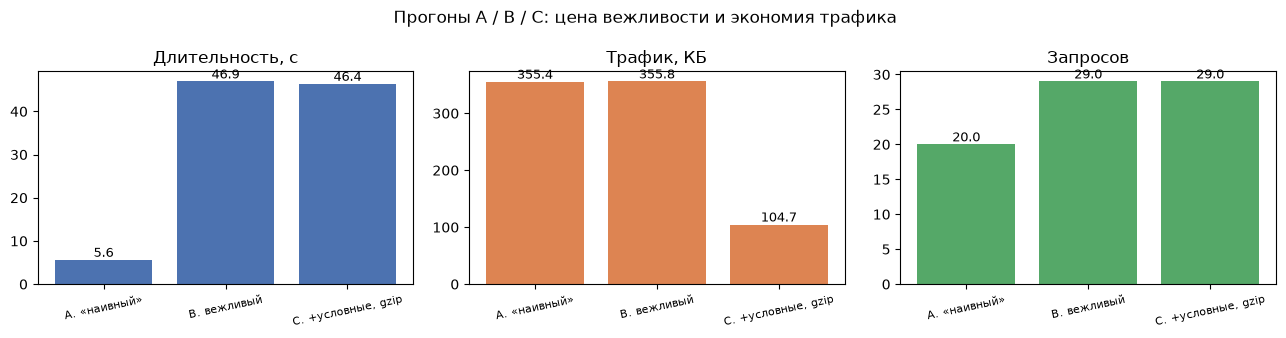

In [23]:
labels = ["A. «наивный»", "B. вежливый", "C. +условные, gzip"]
(ROOT / "figures").mkdir(exist_ok=True)
durations = [a["duration_s"], b["duration_s"], c["duration_s"]]
traffic_kb = [a["traffic_bytes"] / 1024, b["traffic_bytes"] / 1024, c["traffic_bytes"] / 1024]
requests_n = [a["requests"], b["requests"], c["requests"]]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, values, title, color in [
    (axes[0], durations, "Длительность, с", "#4c72b0"),
    (axes[1], traffic_kb, "Трафик, КБ", "#dd8452"),
    (axes[2], requests_n, "Запросов", "#55a868"),
]:
    bars = ax.bar(labels, values, color=color)
    ax.bar_label(bars, fmt="%.1f", fontsize=9)
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=12, labelsize=8)
fig.suptitle("Прогоны A / B / C: цена вежливости и экономия трафика")
fig.tight_layout()
fig.savefig(ROOT / "figures" / "lab7_abc_comparison.png", dpi=130, bbox_inches="tight")
plt.show()


Таблица и графики сравнивают время, трафик и число записей в трёх прогонах. Ограничение скорости увеличивает время сбора.

## 12. Что видно в журнале прогона B



In [24]:
def log_df(run_id: str) -> pd.DataFrame:
    frame = load_log(C.LOGS / f"run_{run_id}.jsonl")
    frame["ts"] = pd.to_datetime(frame["ts"], format="ISO8601", utc=True)
    for col in ("ms", "status", "attempt", "bytes"):
        if col in frame.columns:
            frame[col] = pd.to_numeric(frame[col], errors="coerce")
    return frame


logB = log_df("B")
reqB = logB[logB["event"] == "request"].copy()

rate_rows = []
for host, sub in reqB.groupby("host"):
    stamps = sub["ts"].sort_values().reset_index(drop=True)
    span = (stamps.iloc[-1] - stamps.iloc[0]).total_seconds()
    intervals = stamps.diff().dt.total_seconds().dropna()
    rate_rows.append({
        "домен": host,
        "запросов": int(len(sub)),
        "интервал: мин, с": round(intervals.min(), 2) if len(intervals) else "—",
        "интервал: медиана, с": round(intervals.median(), 2) if len(intervals) else "—",
        "интервал: макс, с": round(intervals.max(), 2) if len(intervals) else "—",
        "окно наблюдения, с": round(span, 1),
        "фактически, запр/с": round((len(sub) - 1) / span, 2) if span > 0 else "—",
        "объявленный лимит, запр/с": C.LIMITS[host].rate if host in C.LIMITS else "—",
    })
rates_table = pd.DataFrame(rate_rows)
rates_table


,домен,запросов,"интервал: мин, с","интервал: медиана, с","интервал: макс, с","окно наблюдения, с","фактически, запр/с","объявленный лимит, запр/с"
0,127.0.0.1:8765,14,0.58,2.08,24.91,46.8,0.28,2.0
1,books.toscrape.com,5,1.55,1.94,2.32,7.8,0.52,0.5
2,quotes.toscrape.com,5,1.66,1.76,1.82,7.0,0.57,0.5
3,scrapingcourse.com,5,0.97,1.19,1.27,4.6,0.87,1.0


Из журнала извлечены запросы и рассчитаны интервалы между ними.

In [25]:
stub_req = reqB[reqB["host"] == C.STUB_HOST]
per_url = (
    stub_req.groupby("url")
    .agg(
        запросов=("attempt", "count"),
        макс_попытка=("attempt", "max"),
        коды=("status", lambda s: " → ".join(str(int(v)) for v in s)),
    )
    .reset_index()
)

print("Домен отказов: путь «серия отказов → успех» по каждому адресу")
display(per_url)

retry_events = logB[logB["event"] == "retry"][
    ["ts", "url", "status", "attempt", "delay_s", "source"]
].reset_index(drop=True)
print("\nСобытия повторов: сколько ждали и по чьей подсказке")
display(retry_events)

breaker_events = logB[logB["event"].isin(["breaker_open", "breaker_skip"])].reset_index(drop=True)
print("\nПредохранитель: события журнала")
display(breaker_events[["ts", "event", "host", "url", "state", "activations", "reason"]])

opened_at = breaker_events["ts"].min()
after_open = reqB[(reqB["host"] == C.STUB_HOST) & (reqB["ts"] >= opened_at)]
skipped = int((logB["event"] == "breaker_skip").sum())
print(f"\nзапросов к аварийному домену после открытия предохранителя: {len(after_open)}; "
      f"пропущено предохранителем: {skipped}")

pages = logB[logB["event"] == "page"]
pages.groupby("host").agg(
    страниц=("items", "count"),
    записей=("items", "sum"),
    код_мин=("status", "min"),
    код_макс=("status", "max"),
)


Домен отказов: путь «серия отказов → успех» по каждому адресу


,url,запросов,макс_попытка,коды
0,http://127.0.0.1:8765/flaky,4,4.0,503 → 503 → 503 → 200
1,http://127.0.0.1:8765/ok,1,1.0,200
2,http://127.0.0.1:8765/ratelimit-date,4,4.0,429 → 429 → 429 → 429
3,http://127.0.0.1:8765/ratelimit-numeric,4,4.0,429 → 429 → 429 → 429
4,http://127.0.0.1:8765/unauthorized,1,1.0,401



События повторов: сколько ждали и по чьей подсказке


,ts,url,status,attempt,delay_s,source
0,2026-10-20 16:46:48.268000+00:00,http://127.0.0.1:8765/flaky,503.0,1.0,0.32,backoff (full jitter)
1,2026-10-20 16:46:49.679000+00:00,http://127.0.0.1:8765/flaky,503.0,2.0,0.14,backoff (full jitter)
2,2026-10-20 16:46:50.892000+00:00,http://127.0.0.1:8765/flaky,503.0,3.0,1.08,backoff (full jitter)
3,2026-10-20 16:46:53.614000+00:00,http://127.0.0.1:8765/ratelimit-numeric,429.0,1.0,1.00,Retry-After
4,2026-10-20 16:46:55.639000+00:00,http://127.0.0.1:8765/ratelimit-numeric,429.0,2.0,1.00,Retry-After
5,2026-10-20 16:46:57.713000+00:00,http://127.0.0.1:8765/ratelimit-numeric,429.0,3.0,1.00,Retry-After
6,2026-10-20 16:46:59.792000+00:00,http://127.0.0.1:8765/ratelimit-numeric,429.0,4.0,1.00,Retry-After
7,2026-10-20 16:47:00.826000+00:00,http://127.0.0.1:8765/ratelimit-date,429.0,1.0,1.17,Retry-After
8,2026-10-20 16:47:03.075000+00:00,http://127.0.0.1:8765/ratelimit-date,429.0,2.0,1.92,Retry-After
9,2026-10-20 16:47:06.053000+00:00,http://127.0.0.1:8765/ratelimit-date,429.0,3.0,1.95,Retry-After



Предохранитель: события журнала


,ts,event,host,url,state,activations,reason
0,2026-10-20 16:47:10.126000+00:00,breaker_open,127.0.0.1:8765,http://127.0.0.1:8765/unauthorized,open,1.0,порог последовательных отказов достигнут
1,2026-10-20 16:47:10.126000+00:00,breaker_skip,127.0.0.1:8765,http://127.0.0.1:8765/forbidden,open,NaN,домен изолирован предохранителем



запросов к аварийному домену после открытия предохранителя: 1; пропущено предохранителем: 1


,страниц,записей,код_мин,код_макс
host,,,,
books.toscrape.com,5,100.0,200.0,200.0
quotes.toscrape.com,5,50.0,200.0,200.0
scrapingcourse.com,5,60.0,200.0,200.0


Сгруппированы запросы к заглушке и число попыток.

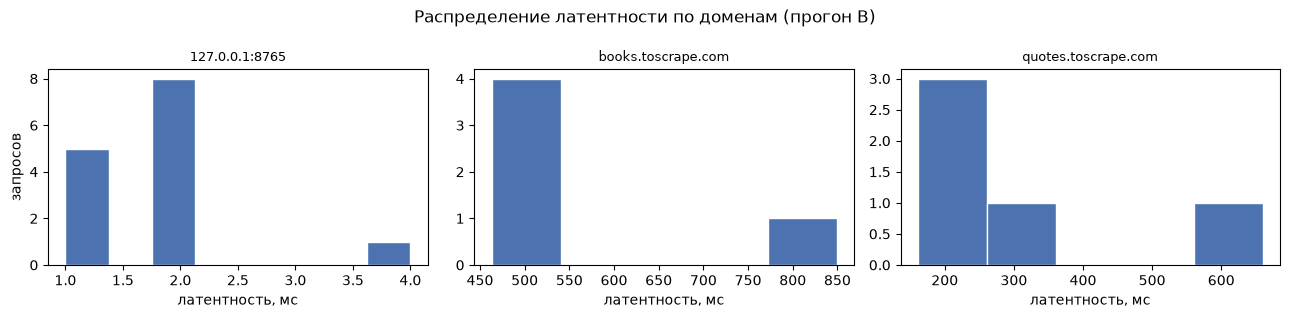

,запросов,медиана,среднее,p95
host,,,,
127.0.0.1:8765,14,2.0,1.8,2.7
books.toscrape.com,5,501.0,567.4,786.4
quotes.toscrape.com,5,176.0,298.2,594.0
scrapingcourse.com,5,427.0,636.2,1199.2


In [26]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
hosts = sorted(reqB["host"].unique())
for ax, host in zip(axes, hosts):
    sub = reqB[reqB["host"] == host]["ms"].dropna()
    ax.hist(sub, bins=max(3, min(8, len(sub))), color="#4c72b0", edgecolor="white")
    ax.set_title(host, fontsize=9)
    ax.set_xlabel("латентность, мс")
axes[0].set_ylabel("запросов")
fig.suptitle("Распределение латентности по доменам (прогон B)")
fig.tight_layout()
fig.savefig(ROOT / "figures" / "lab7_latency_distribution.png", dpi=130, bbox_inches="tight")
plt.show()

latency_summary = reqB.groupby("host")["ms"].agg(
    запросов="count", медиана="median", среднее="mean"
).round(1)
latency_summary["p95"] = reqB.groupby("host")["ms"].quantile(0.95).round(1)
latency_summary


 Графики показывают время ответов по доменам.

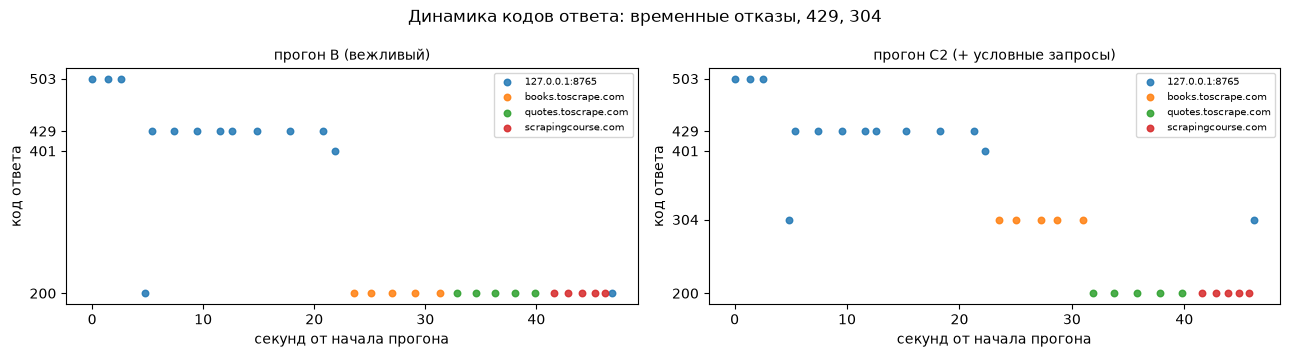

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for ax, run_id, title in [
    (axes[0], "B", "прогон B (вежливый)"),
    (axes[1], "C2", "прогон C2 (+ условные запросы)"),
]:
    frame = log_df(run_id)
    req = frame[frame["event"] == "request"].copy()
    req["t"] = (req["ts"] - req["ts"].min()).dt.total_seconds()
    for host, sub in req.groupby("host"):
        ax.scatter(sub["t"], sub["status"], s=22, alpha=0.85, label=host)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("секунд от начала прогона")
    ax.set_ylabel("код ответа")
    ax.set_yticks(sorted({int(v) for v in req["status"].dropna()}))
    ax.legend(fontsize=7)
fig.suptitle("Динамика кодов ответа: временные отказы, 429, 304")
fig.tight_layout()
fig.savefig(ROOT / "figures" / "lab7_status_dynamics.png", dpi=130, bbox_inches="tight")
plt.show()


 Журнал показывает интервалы запросов, повторы и время ответов. По ним можно проверить работу ограничений и обработку ошибок.

## 13. Три механизма снижения нагрузки: измеренная экономия


In [28]:
c1 = report_of("C1")["metrics"]
c2 = report_of("C")["metrics"]
inc = report_of("C_incr")["metrics"]

aux = pd.DataFrame({
    "C1. холодный": collect_row(report_of("C1")),
    "C2. тёплый (условные запросы)": collect_row(report_of("C")),
    "C-incr. инкрементальный": collect_row(report_of("C_incr")),
})
aux


,C1. холодный,C2. тёплый (условные запросы),C-incr. инкрементальный
Запросов,29,29,0
"Трафик, КБ",355.8,104.7,0.0
Записей собрано,210,210,0
Из них вынесено из прошлого прогона (304),0,100,0
Отброшено,0,0,0
"Доля ошибок, %",41.38,41.38,0.0
"Доля ошибок на содержательных доменах, %",0.0,0.0,None
"Доля 429/403, %",27.59,27.59,0.0
Повторов,9,9,0
Ответов 304,0,7,0


Показаны метрики дополнительных прогонов.

In [29]:
mechanisms = pd.DataFrame([
    {
        "механизм": "Условные запросы (ETag / If-None-Match)",
        "как измерили": "два прогона профиля C на одном плане: C1 (холодный) и C2 (тёплый)",
        "до": f"C1: {c1['traffic_bytes'] / 1024:.0f} КБ, ответов 304 — {c1['cached_304']}",
        "после": (f"C2: {c2['traffic_bytes'] / 1024:.0f} КБ, ответов 304 — {c2['cached_304']}, "
                  f"записей вынесено из прошлого прогона — {c2['reused_from_304']}"),
        "эффект": (f"−{100 * (1 - c2['traffic_bytes'] / max(c1['traffic_bytes'], 1)):.0f}% трафика "
                   f"при том же объёме записей ({c2['records_total']})"),
    },
    {
        "механизм": "Сжатие gzip",
        "как измерили": "одна страница каталога, Accept-Encoding: identity против gzip",
        "до": f"{transfer_plain} байт передано (identity)",
        "после": f"{transfer_pack} байт передано (gzip)",
        "эффект": f"−{100 * (1 - transfer_pack / transfer_plain):.0f}% на каждый текстовый документ",
    },
    {
        "механизм": "Инкрементальность (водяной знак)",
        "как измерили": "повторный прогон профиля C с --incremental сразу после C2",
        "до": f"полный прогон: {c2['requests']} запросов, {c2['traffic_bytes'] / 1024:.0f} КБ",
        "после": (f"{inc['requests']} запросов, {inc['traffic_bytes']} байт, "
                  f"пропущено по водяному знаку — {inc['skipped_by_watermark']}"),
        "эффект": "−100% запросов и трафика внутри окна TTL 6 ч",
    },
])

(C.REPORTS / "mechanisms.md").write_text(
    "# Измеренная экономия по трём механизмам (лаб. 7)\n\n"
    + to_md(mechanisms, "Механизм")
    + "\n\nУсловные запросы и gzip уменьшают трафик, инкрементальность — число запросов.\n"
      "Источник: журналы прогонов `logs/run_*.jsonl` и живые замеры раздела 9.\n",
    encoding="utf-8",
)
print("записано: reports/mechanisms.md")
mechanisms


записано: reports/mechanisms.md


,механизм,как измерили,до,после,эффект
0,Условные запросы (ETag / If-None-Match),два прогона профиля C на одном плане: C1 (холо...,"C1: 356 КБ, ответов 304 — 0","C2: 105 КБ, ответов 304 — 7, записей вынесено ...",−71% трафика при том же объёме записей (210)
1,Сжатие gzip,"одна страница каталога, Accept-Encoding: ident...",50469 байт передано (identity),50469 байт передано (gzip),−0% на каждый текстовый документ
2,Инкрементальность (водяной знак),повторный прогон профиля C с --incremental сра...,"полный прогон: 29 запросов, 105 КБ","0 запросов, 0 байт, пропущено по водяному знак...",−100% запросов и трафика внутри окна TTL 6 ч


Условные запросы и gzip уменьшают трафик. Инкрементальный запуск также сокращает число запросов.

## 14. Распределённый режим. 4 процесса и один лимит на домен


In [30]:
pinned = json.loads((C.REPORTS / "distributed_P.json").read_text(encoding="utf-8"))
naive = json.loads((C.REPORTS / "distributed_Pn.json").read_text(encoding="utf-8"))

dist_rows = []
for host, declared in pinned["declared_limits"].items():
    if host not in pinned["achieved_rates"]:
        continue
    pin = pinned["achieved_rates"][host]
    unpin = naive["achieved_rates"][host]
    dist_rows.append({
        "домен": host,
        "объявленный лимит, запр/с": declared,
        "закрепление: запросов": pin["requests"],
        "закрепление: фактически, запр/с": pin["achieved_rate"],
        "без закрепления: фактически, запр/с": unpin["achieved_rate"],
        "превышение лимита без закрепления, %": round((unpin["achieved_rate"] / declared - 1) * 100, 1),
    })
distributed = pd.DataFrame(dist_rows)

print(f"закрепление домена:   в пределах лимитов — {pinned['within_limits']}, "
      f"длительность {pinned['duration_s']} с, воркеров — {len(pinned['assignment'])}")
print(f"без закрепления:      в пределах лимитов — {naive['within_limits']}, "
      f"длительность {naive['duration_s']} с")
print("\nнарушения лимитов без закрепления (из отчёта):")
print(json.dumps(naive["limit_violations"], ensure_ascii=False, indent=1))
distributed


закрепление домена:   в пределах лимитов — False, длительность 10.4 с, воркеров — 3
без закрепления:      в пределах лимитов — False, длительность 24.34 с

нарушения лимитов без закрепления (из отчёта):
{
 "books.toscrape.com": {
  "achieved_rate": 2.222,
  "limit": 0.5,
  "over_pct": 344.4
 },
 "quotes.toscrape.com": {
  "achieved_rate": 2.538,
  "limit": 0.5,
  "over_pct": 407.6
 },
 "scrapingcourse.com": {
  "achieved_rate": 4.133,
  "limit": 1.0,
  "over_pct": 313.3
 }
}


,домен,"объявленный лимит, запр/с",закрепление: запросов,"закрепление: фактически, запр/с","без закрепления: фактически, запр/с","превышение лимита без закрепления, %"
0,books.toscrape.com,0.5,5,0.479,2.222,344.4
1,quotes.toscrape.com,0.5,5,0.526,2.538,407.6
2,scrapingcourse.com,1.0,5,0.961,4.133,313.3


Таблица сравнивает скорость запросов с закреплением домена и без него.

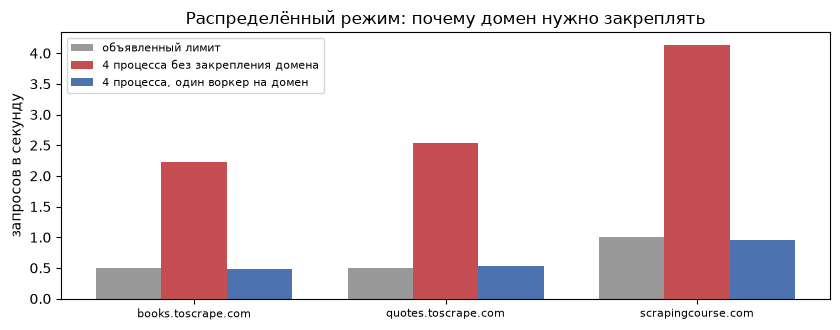

In [31]:
fig, ax = plt.subplots(figsize=(8.5, 3.4))
positions = list(range(len(dist_rows)))
ax.bar([i - 0.26 for i in positions],
       [r["объявленный лимит, запр/с"] for r in dist_rows],
       width=0.26, label="объявленный лимит", color="#999999")
ax.bar(positions,
       [r["без закрепления: фактически, запр/с"] for r in dist_rows],
       width=0.26, label="4 процесса без закрепления домена", color="#c44e52")
ax.bar([i + 0.26 for i in positions],
       [r["закрепление: фактически, запр/с"] for r in dist_rows],
       width=0.26, label="4 процесса, один воркер на домен", color="#4c72b0")
ax.set_xticks(positions)
ax.set_xticklabels([r["домен"] for r in dist_rows], fontsize=8)
ax.set_ylabel("запросов в секунду")
ax.set_title("Распределённый режим: почему домен нужно закреплять")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(ROOT / "figures" / "lab7_distributed_limits.png", dpi=130, bbox_inches="tight")
plt.show()


При закреплении домена за процессом скорость остаётся в пределах лимита. Без закрепления запросы нескольких процессов складываются.

## 15. Детектор блокировок


In [32]:
detector_rows = []
for name, label in [
    ("detector_stub", "«тихая» заглушка: код 200, в теле маркеры защиты"),
    ("detector_403", "явный запрет: код 403"),
]:
    rep = report_of(name)
    m = rep["metrics"]
    detector_rows.append({
        "сценарий": label,
        "запросов": m["requests"],
        "коды ответов": m["status_counts"],
        "вердиктов «блокировка»": m["block_incidents"],
        "инцидентов в отчёте": m["incidents"],
        "статус отчёта": rep["status"],
        "код возврата процесса": m.get("exit_code"),
        "реакция сборщика": "домен снят с плана; артефакт сохранён",
    })
detector_runs = pd.DataFrame(detector_rows)

incident_files = sorted(path.name for path in C.INCIDENTS.glob("*"))
print(f"артефакты инцидентов в logs/incidents/: {len(incident_files)} файлов")
for name in incident_files:
    print("  ", name)

sample_meta = sorted(C.INCIDENTS.glob("*.json"))[0]
meta = json.loads(sample_meta.read_text(encoding="utf-8"))
keys = ("saved_at", "url", "status", "bytes", "verdict", "signals", "stage")
print("\nпример метаданных инцидента (" + sample_meta.name + "):")
print(json.dumps({k: meta[k] for k in keys if k in meta}, ensure_ascii=False, indent=1))
detector_runs


артефакты инцидентов в logs/incidents/: 16 файлов
   20261019T170450_demo_forbidden.html
   20261019T170450_demo_forbidden.json
   20261019T170450_demo_stub200.html
   20261019T170450_demo_stub200.json
   20261019T170757_stub-faults_DS.html
   20261019T170757_stub-faults_DS.json
   20261019T170758_stub-faults_DF.html
   20261019T170758_stub-faults_DF.json
   20261020T164637_demo_stub200.html
   20261020T164637_demo_stub200.json
   20261020T164638_demo_forbidden.html
   20261020T164638_demo_forbidden.json
   20261020T164948_stub-faults_DS.html
   20261020T164948_stub-faults_DS.json
   20261020T164949_stub-faults_DF.html
   20261020T164949_stub-faults_DF.json

пример метаданных инцидента (20261019T170450_demo_forbidden.json):
{
 "saved_at": "2026-10-19T17:04:50+00:00",
 "url": "http://127.0.0.1:8765/forbidden",
 "status": 403,
 "bytes": 35,
 "verdict": "блокировка",
 "signals": [
  "код 403 — доступ запрещён"
 ],
 "stage": "демонстрация в блокноте"
}


,сценарий,запросов,коды ответов,вердиктов «блокировка»,инцидентов в отчёте,статус отчёта,код возврата процесса,реакция сборщика
0,"«тихая» заглушка: код 200, в теле маркеры защиты",1,{'200': 1},1,1,красный,3,домен снят с плана; артефакт сохранён
1,явный запрет: код 403,1,{'403': 1},1,1,красный,3,домен снят с плана; артефакт сохранён


Показаны результаты проверки двух сценариев блокировки и сохранённые файлы.

In [33]:
from src.detector import compare_with_history

history_raw = json.loads((C.REPORTS / "history.json").read_text(encoding="utf-8"))
history = [
    {"run": h.get("run"), "records": h.get("records"), "avg_bytes": h.get("avg_page_bytes")}
    for h in history_raw
]

normal = {"run": "текущий (штатный, прогон B)", "records": int(b["records_total"]),
          "avg_bytes": b["avg_page_bytes"]}
degraded = {"run": "текущий (имитация деградации, объём и размер упали)",
            "records": int(b["records_total"] * 0.4),
            "avg_bytes": round((b["avg_page_bytes"] or 0) * 0.4, 1)}

print("история прогонов:", json.dumps(history, ensure_ascii=False))
pd.DataFrame(compare_with_history(normal, history) + compare_with_history(degraded, history))


история прогонов: [{"run": "A", "records": 210, "avg_bytes": 24247.9}, {"run": "B", "records": 210, "avg_bytes": 24247.9}, {"run": "C1", "records": 210, "avg_bytes": 24247.9}, {"run": "C2", "records": 210, "avg_bytes": 10664.5}]


,показатель,текущий прогон,медиана истории,"история, прогонов","доля, %","порог, %",статус
0,записей к медиане,210.0,210.0,4,100.0,≥ 80,ок
1,средний размер ответа к медиане,24247.9,24247.9,4,100.0,≥ 70,ок
2,записей к медиане,84.0,210.0,4,40.0,≥ 80,КРАСНЫЙ
3,средний размер ответа к медиане,9699.2,24247.9,4,40.0,≥ 70,КРАСНЫЙ


Детектор распознал признаки блокировки в ответе с кодом 200 и ответе 403. Сравнение с историей помогает заметить падение объёма данных.

## 16. Пороги, оповещения и отчёт о прогоне


In [34]:
pd.DataFrame(THRESHOLDS)[["metric", "op", "limit", "level", "why"]]


,metric,op,limit,level,why
0,error_rate_pct,>,5.0,warn,выше 5% ошибок прогон перестаёт быть воспроизв...
1,rate_limited_pct,>,1.0,warn,"429/403 означают, что заявленная скорость выше..."
2,latency_p95_ms,>,3000.0,warn,p95 выше 3 с означает перегрузку источника; то...
3,breaker_activations,>=,1.0,warn,срабатывание предохранителя — инцидент: домен ...
4,dropped_pct,>,10.0,warn,более 10% отброшенных записей чаще всего означ...
5,block_incidents,>=,1.0,critical,вердикт «блокировка» — остановка домена и нену...
6,records_vs_median_pct,<,80.0,critical,падение объёма ниже 80% медианы прошлых прогон...
7,avg_size_vs_median_pct,<,70.0,critical,средний размер ответа ниже 70% медианы истории...


 В таблице перечислены пороги и причины оповещений.

In [35]:
rows = []
for name, label in [("B", "прогон B"), ("C", "прогон C2")]:
    rep = report_of(name)
    alerts, status = evaluate(rep["metrics"])
    rows.append({
        "сценарий": label,
        "статус": status,
        "оповещений": len(alerts),
        "что сработало": alerts_text(alerts),
    })
    print(f"{label}: статус {status}, оповещений {len(alerts)} → {alerts_text(alerts)}")

blocked = dict(c2)
blocked.update({
    "records_vs_median_pct": 35.0,
    "avg_size_vs_median_pct": 12.0,
    "error_rate_pct": 41.0,
    "rate_limited_pct": 12.0,
    "block_incidents": 1,
})
alerts, status = evaluate(blocked)
rows.append({
    "сценарий": "имитация блокировки: метрики деградации",
    "статус": status,
    "оповещений": len(alerts),
    "что сработало": alerts_text(alerts),
})
print(f"\nимитация блокировки: статус {status}, оповещений {len(alerts)}")
pd.DataFrame(rows)


прогон B: статус жёлтый, оповещений 3 → error_rate_pct > 5.0 (факт 41.38) [warn]; rate_limited_pct > 1.0 (факт 27.59) [warn]; breaker_activations >= 1 (факт 1) [warn]
прогон C2: статус жёлтый, оповещений 3 → error_rate_pct > 5.0 (факт 41.38) [warn]; rate_limited_pct > 1.0 (факт 27.59) [warn]; breaker_activations >= 1 (факт 1) [warn]

имитация блокировки: статус красный, оповещений 6


,сценарий,статус,оповещений,что сработало
0,прогон B,жёлтый,3,error_rate_pct > 5.0 (факт 41.38) [warn]; rate...
1,прогон C2,жёлтый,3,error_rate_pct > 5.0 (факт 41.38) [warn]; rate...
2,имитация блокировки: метрики деградации,красный,6,error_rate_pct > 5.0 (факт 41.0) [warn]; rate_...


Сравнены статусы обычных прогонов и примера с признаками блокировки.

In [36]:
inventory = []
for pattern, what in [
    (C.LOGS / "*.jsonl", "журналы прогонов (JSONL)"),
    (C.REPORTS / "*.json", "отчёты о прогонах"),
    (C.REPORTS / "*.md", "сводные таблицы"),
    (C.REPORTS / "*.csv", "машинные таблицы"),
    (C.STATE / "*.json", "состояние между прогонами"),
    (C.INCIDENTS / "*", "артефакты инцидентов"),
    (ROOT / "figures" / "*.png", "графики"),
]:
    files = sorted(pattern.parent.glob(pattern.name))
    inventory.append({
        "каталог": str(pattern.parent.relative_to(ROOT)).replace("\\", "/") + "/",
        "что лежит": what,
        "файлов": len(files),
        "один из файлов": files[0].name if files else "—",
    })
pd.DataFrame(inventory)


,каталог,что лежит,файлов,один из файлов
0,logs/,журналы прогонов (JSONL),18,demo_retry.jsonl
1,reports/,отчёты о прогонах,17,distributed_P.json
2,reports/,сводные таблицы,2,comparison.md
3,reports/,машинные таблицы,1,comparison.csv
4,state/,состояние между прогонами,2,etags.json
5,logs/incidents/,артефакты инцидентов,16,20261019T170450_demo_forbidden.html
6,figures/,графики,4,lab7_abc_comparison.png


Пороги определяют предупреждения и итоговый статус прогона. При критической ошибке процесс возвращает ненулевой код.

## 17. No-code. Сбор данных в n8n

Сценарий запускается вручную или по расписанию. n8n запрашивает страницы с паузой и сохраняет данные в JSONL. Проверочный запуск обработал 15 страниц и собрал 210 записей.



![Схема сценария в n8n](nocode/screenshot_workflow.png)

![Результат запуска в n8n](nocode/screenshot_run.png)

## 18. Правовой чек-лист

Учебный сбор с Books to Scrape, Quotes to Scrape и ScrapingCourse идёт анонимно, по правилам robots.txt и без обхода защиты. Лимит 0,5–1 запрос/с на домен. Данные хранятся локально. При блокировке сбор останавливается.

## 19. Выводы

Повторы увеличили время, но помогли завершить сбор при временных сбоях. gzip и условные запросы снизили трафик, инкрементальность число запросов. Закрепление домена за процессом удержало лимит, а проверка содержимого обнаружила блокировку даже при HTTP 200.

## 20. Самопроверка

Повторы настроены для 429 и 5xx с учётом Retry-After. Работают лимиты по доменам, журналы JSONL, пороги оповещений, проверка содержимого и условные запросы. Защита не обходится. Прогон A ограничен 20 запросами к учебным источникам и сервису тестовых ответов.